# Phase 3, piece 1: analytical baseline

Before training any ML model, I fit a simple formula. The learned models have to beat it, otherwise they aren't adding anything.

Data: the laptop sweep (`sweep_v2_nvidia_geforce_rtx_5070_ti_laptop_gpu.csv`). I keep only the `ok` rows and average the 3 repeats of each config.

Split: train on distilGPT-2, GPT-2, Qwen2.5-0.5B and TinyLlama-1.1B. Test on GPT-2 medium (355M). It sits in the middle of the training sizes, so this tests interpolation to a new model.

## The formulas

Energy per token ≈ a · params / batch + c

127 of the 128 tokens come from decode. Each decode step reads all the weights once, no matter the batch size, and that cost is split across the batch. So the weight-reading part is params / batch. c is a fixed cost per token. Prefill and prompt length are left out to keep it simple.

TPOT ≈ a · params + c

TPOT is the time for one decode step. It isn't split across the batch, so there's no / batch. A step reads all the weights (params) plus some fixed overhead (c). This formula can't show TPOT going up at large batch sizes.

Params are in billions so a is an easy number to read.

## Two ways to fit it

Raw space: normal least squares on the values, minimizing Σ (y − ŷ)². This minimizes absolute error, so the big values (batch 1, around 1600 mJ) dominate and the small ones (around 6 mJ at batch 128) get ignored. That's why train MAPE came out worse than test MAPE.

Log space: same formula, but minimizing Σ (log y − log ŷ)². A log difference is a ratio, so being 20% off costs the same at 6 mJ and at 1600 mJ. That matches MAPE better. This isn't linear in a and c anymore, so I use `scipy.optimize.least_squares` with a, c ≥ 0.

In [54]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import least_squares

DATA = Path("../data") if Path("../data").exists() else Path("data")
HELD_OUT = "openai-community/gpt2-medium"

runs = pd.read_csv(DATA / "sweep_v2_nvidia_geforce_rtx_5070_ti_laptop_gpu.csv")
ok = runs[runs["status"] == "ok"]

# One row per configuration: mean over the 3 repeats. Targets in mJ and ms for readability.
cfg = (ok.groupby(["model", "params", "batch_size", "prompt_len"], as_index=False)
         .agg(energy_mj=("energy_per_token_j", lambda s: s.mean() * 1000),
              tpot_ms=("tpot_s", lambda s: s.mean() * 1000)))
cfg["params_b"] = cfg["params"] / 1e9

train = cfg[cfg["model"] != HELD_OUT].reset_index(drop=True)
test = cfg[cfg["model"] == HELD_OUT].reset_index(drop=True)
print(f"train: {len(train)} configs from {train['model'].nunique()} models   test: {len(test)} configs ({HELD_OUT})")

train: 95 configs from 4 models   test: 24 configs (openai-community/gpt2-medium)


In [55]:
# Each baseline = one feature x (built from the inputs) and the model y = a * x + c.
BASELINES = {
    "energy_mj": lambda df: df["params_b"] / df["batch_size"],   # energy per token ~ a * params / batch + c
    "tpot_ms":   lambda df: df["params_b"],                      # TPOT             ~ a * params + c
}


def fit_raw(target):
    # Raw space: ordinary least squares on the training rows, solve [x 1] @ [a c] ~ y.
    # Minimizes absolute error, so large-valued rows dominate.
    x = BASELINES[target](train)
    X = np.column_stack([x, np.ones(len(x))])
    (a, c), *_ = np.linalg.lstsq(X, train[target], rcond=None)
    return a, c


def fit_log(target):
    # Log space: same formula, minimize sum of (log(a*x + c) - log(y))^2 on the training rows.
    # Equal weight on every row's relative error. Started from the raw fit, a and c kept >= 0.
    x = BASELINES[target](train).to_numpy()
    y = train[target].to_numpy()
    start = np.clip(fit_raw(target), 1e-6, None)
    res = least_squares(lambda th: np.log(th[0] * x + th[1]) - np.log(y), x0=start,
                        bounds=([0, 0], [np.inf, np.inf]))
    assert res.success, res.message
    return tuple(res.x)



def predict(target, df, a, c):
    return a * BASELINES[target](df) + c


def mape(y, y_hat):
    return float(np.mean(np.abs(y_hat - y) / y) * 100)


FITS = {"raw": fit_raw, "log": fit_log}
coefs = {(space, t): f(t) for space, f in FITS.items() for t in BASELINES}
for (space, t), (a, c) in coefs.items():
    print(f"{space:3s}  {t:10s}  a = {a:9.4f}   c = {c:8.4f}")

raw  energy_mj   a = 1553.8029   c =  69.5532
raw  tpot_ms     a =   29.7625   c =   6.2862
log  energy_mj   a = 2503.1275   c =  14.7711
log  tpot_ms     a =   36.3428   c =   1.7400


In [56]:
# Raw-space and log-space fits side by side, so the difference is visible.
results = pd.DataFrame([
    {"target": t, "fit": space,
     "train MAPE (%)": mape(train[t], predict(t, train, *coefs[space, t])),
     "test MAPE, GPT-2 medium (%)": mape(test[t], predict(t, test, *coefs[space, t]))}
    for t in BASELINES for space in FITS
]).set_index(["target", "fit"]).round(1)
results

train MAPE (%)  test MAPE, GPT-2 medium (%)
target    fit                                             
energy_mj raw           124.3                         32.6
          log            35.6                         28.7
tpot_ms   raw            74.9                         52.2
          log            44.0                         41.7

### MAPE per model

Shows which models the formula fits well and which it doesn't, for both fits.

In [57]:
rows = []
for (space, t), ac in coefs.items():
    for name, part in [("train", train), ("test", test)]:
        p = part.assign(pred=predict(t, part, *ac))
        for model, g in p.groupby("model"):
            rows.append({"target": t, "fit": space, "split": name, "model": model,
                         "MAPE (%)": mape(g[t], g["pred"])})
pd.DataFrame(rows).pivot_table(index=["split", "model"], columns=["target", "fit"],
                               values="MAPE (%)").round(1)

target                             energy_mj        tpot_ms       
fit                                      log    raw     log    raw
split model                                                       
test  openai-community/gpt2-medium      28.7   32.6    41.7   52.2
train Qwen/Qwen2.5-0.5B                 26.1   33.2    24.4   19.8
      TinyLlama/TinyLlama_v1.1          52.9   22.6    77.5   68.9
      distilbert/distilgpt2             48.7  305.7    48.5  143.6
      openai-community/gpt2             15.3  131.7    26.9   67.1

## Predicted vs actual

Both axes are log scale, so the same distance from the dashed line means the same percent error. Points on the line are perfect.

Top row is the raw-space fit, bottom row is the log-space fit. Each column uses the same axes.

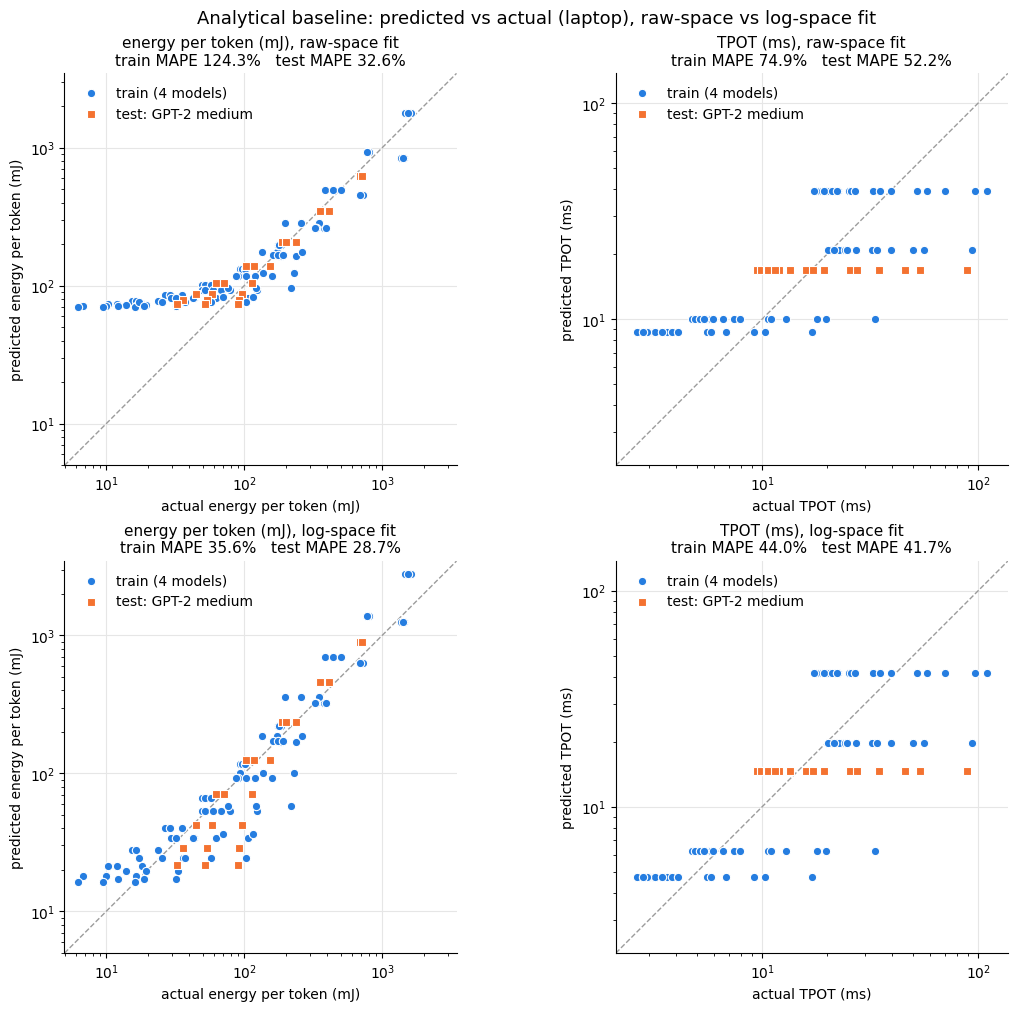

In [58]:
LABELS = {"energy_mj": "energy per token (mJ)", "tpot_ms": "TPOT (ms)"}
fig, axes = plt.subplots(len(FITS), len(BASELINES), figsize=(11, 10), constrained_layout=True)
for col, t in enumerate(BASELINES):
    # One axis range per column (target), covering both fits' predictions.
    allpred = np.concatenate([predict(t, cfg, *coefs[sp, t]) for sp in FITS])
    lo = min(cfg[t].min(), allpred.min()) * 0.8
    hi = max(cfg[t].max(), allpred.max()) * 1.25
    for row, space in enumerate(FITS):
        ax = axes[row, col]
        for name, part, color, marker in [("train (4 models)", train, "#257de0", "o"),
                                          ("test: GPT-2 medium", test, "#f47230", "s")]:
            ax.scatter(part[t], predict(t, part, *coefs[space, t]), s=36, color=color, marker=marker,
                       edgecolor="white", linewidth=0.8, label=name, zorder=3)
        ax.plot([lo, hi], [lo, hi], color="#9c9c9c", linestyle="--", linewidth=1, zorder=2)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
        ax.set_xlabel(f"actual {LABELS[t]}"); ax.set_ylabel(f"predicted {LABELS[t]}")
        r = results.loc[(t, space)]
        ax.set_title(f"{LABELS[t]}, {space}-space fit\ntrain MAPE {r.iloc[0]:.1f}%   "
                     f"test MAPE {r.iloc[1]:.1f}%", fontsize=11)
        ax.grid(True, color="#e6e6e6", linewidth=0.8); ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.legend(frameon=False, loc="upper left")
fig.suptitle("Analytical baseline: predicted vs actual (laptop), raw-space vs log-space fit", fontsize=13)
plt.show()

# Phase 3, piece 2: linear regression on log features

$$\log y = w_1 \log(\text{params}) + w_2 \log(\text{batch}) + w_3 \log(\text{prompt\_len}) + w_4 \cdot \text{layers} + w_5 \cdot \text{kv\_heads} + b$$

Fit separately for energy per token and for TPOT, with ordinary least squares on log targets. Same split as before.

## Features

- log(params), log(batch), log(prompt_len): a linear model on logs is a power law, y ∝ params^w₁ · batch^w₂ · prompt_len^w₃. The baseline fixed these exponents (energy ∝ params / batch). Here the data picks them.
- prompt_len: the baseline left it out, but every decode step reads the KV cache, which grows with the prompt.
- layers: each layer adds kernel launches to every decode step. This is probably why Qwen2.5-0.5B (24 layers) is about as slow as TinyLlama-1.1B (22 layers).
- kv_heads: controls the KV cache size. Qwen (2) and TinyLlama (4) use grouped-query attention and read much less cache than GPT-2 (12 to 16).

layers and kv_heads are used as raw numbers, not logs.

## Things to keep in mind

There are only 4 training models. params, layers and kv_heads are the same for every row of a model, so together with the intercept the model has 4 numbers it can use to match each training model's average exactly. That can make the train score look better than it really is.

GPT-2 medium has 16 KV heads, more than any training model (12, 12, 2, 4). So for that feature it's outside the training range.

In [59]:
from sklearn.linear_model import LinearRegression

# Model-shape features come from the raw CSV (same for every row of a model).
shape = runs.groupby("model")[["layers", "kv_heads"]].first()
for df in (train, test, cfg):
    df[["layers", "kv_heads"]] = shape.loc[df["model"]].to_numpy()

FEATURES = ["log_params", "log_batch", "log_prompt", "layers", "kv_heads"]


def log_features(df):
    return pd.DataFrame({
        "log_params": np.log(df["params"]),
        "log_batch": np.log(df["batch_size"]),
        "log_prompt": np.log(df["prompt_len"]),
        "layers": df["layers"],
        "kv_heads": df["kv_heads"],
    })


print("training models' shape features:")
print(train.groupby("model")[["params", "layers", "kv_heads"]].first())
print("\nheld out:")
print(test.groupby("model")[["params", "layers", "kv_heads"]].first())

training models' shape features:
                              params  layers  kv_heads
model                                                 
Qwen/Qwen2.5-0.5B          494032768      24         2
TinyLlama/TinyLlama_v1.1  1100048384      22         4
distilbert/distilgpt2       81912576       6        12
openai-community/gpt2      124439808      12        12

held out:
                                 params  layers  kv_heads
model                                                    
openai-community/gpt2-medium  354823168      24        16


In [60]:
# Fit log(target) on the training rows only; predictions go back through exp() before scoring.
linreg = {t: LinearRegression().fit(log_features(train), np.log(train[t])) for t in BASELINES}


def predict_linreg(t, df):
    return np.exp(linreg[t].predict(log_features(df)))


coef_table = pd.DataFrame({t: list(m.coef_) + [m.intercept_] for t, m in linreg.items()},
                          index=FEATURES + ["intercept"]).round(4)
coef_table

,energy_mj,tpot_ms
log_params,0.5105,0.3108
log_batch,-0.6126,0.2380
log_prompt,0.3137,0.1920
layers,0.0688,0.0794
kv_heads,0.0236,0.0061
intercept,-6.8478,-6.4672


How to read the weights: for a log feature the weight is an exponent (energy ∝ params^w). For a raw feature, each extra unit multiplies the target by e^w.

In [61]:
# All three models side by side, same split, same MAPE.
rows = []
for t in BASELINES:
    for name, fn in [("baseline, raw-space fit", lambda df, t=t: predict(t, df, *coefs["raw", t])),
                     ("baseline, log-space fit", lambda df, t=t: predict(t, df, *coefs["log", t])),
                     ("linear regression, log features", lambda df, t=t: predict_linreg(t, df))]:
        rows.append({"target": t, "model": name,
                     "train MAPE (%)": mape(train[t], fn(train)),
                     "test MAPE, GPT-2 medium (%)": mape(test[t], fn(test))})
comparison = pd.DataFrame(rows).set_index(["target", "model"]).round(1)
comparison

train MAPE (%)  \
target    model                                             
energy_mj baseline, raw-space fit                   124.3   
          baseline, log-space fit                    35.6   
          linear regression, log features            23.1   
tpot_ms   baseline, raw-space fit                    74.9   
          baseline, log-space fit                    44.0   
          linear regression, log features            22.7   

                                           test MAPE, GPT-2 medium (%)  
target    model                                                         
energy_mj baseline, raw-space fit                                 32.6  
          baseline, log-space fit                                 28.7  
          linear regression, log features                         90.3  
tpot_ms   baseline, raw-space fit                                 52.2  
          baseline, log-space fit                                 41.7  
          linear regression, log features                         83.0

In [62]:
# Per-model MAPE for the linear model, plus the direction of the held-out error:
# mean predicted / actual above 1 means it over-predicts.
rows = []
for t in BASELINES:
    for name, part in [("train", train), ("test", test)]:
        p = part.assign(pred=predict_linreg(t, part))
        for model, g in p.groupby("model"):
            rows.append({"target": t, "split": name, "model": model,
                         "MAPE (%)": mape(g[t], g["pred"]),
                         "mean predicted / actual": float((g["pred"] / g[t]).mean())})
pd.DataFrame(rows).pivot_table(index=["split", "model"], columns="target",
                               values=["MAPE (%)", "mean predicted / actual"]).round(2)

MAPE (%)         mean predicted / actual  \
target                             energy_mj tpot_ms               energy_mj   
split model                                                                    
test  openai-community/gpt2-medium     90.32   83.00                    1.88   
train Qwen/Qwen2.5-0.5B                23.86   23.01                    1.04   
      TinyLlama/TinyLlama_v1.1         23.70   22.89                    1.04   
      distilbert/distilgpt2            22.27   22.11                    1.03   
      openai-community/gpt2            22.78   22.89                    1.04   

                                            
target                             tpot_ms  
split model                                 
test  openai-community/gpt2-medium    1.79  
train Qwen/Qwen2.5-0.5B               1.04  
      TinyLlama/TinyLlama_v1.1        1.04  
      distilbert/distilgpt2           1.04  
      openai-community/gpt2           1.04

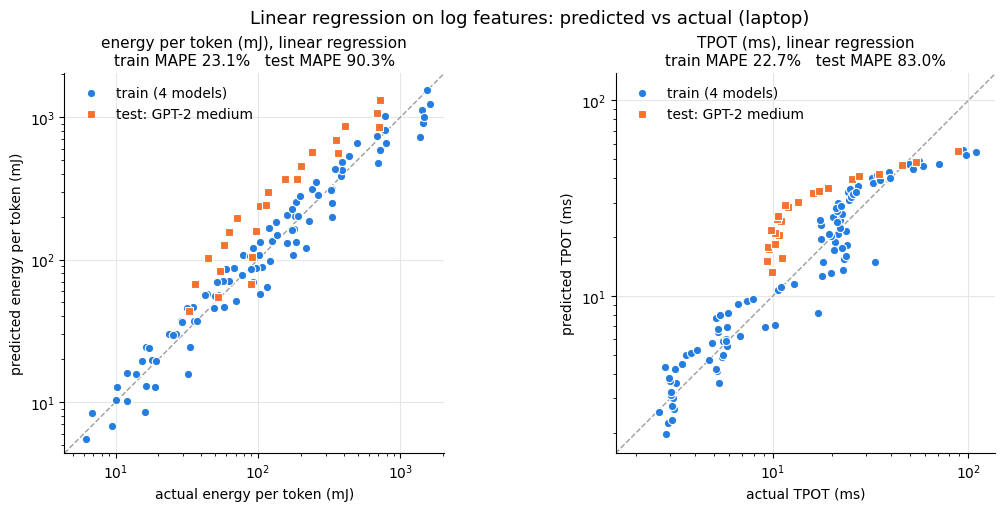

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, t in zip(axes, BASELINES):
    preds = predict_linreg(t, cfg)
    lo = min(cfg[t].min(), preds.min()) * 0.8
    hi = max(cfg[t].max(), preds.max()) * 1.25
    for name, part, color, marker in [("train (4 models)", train, "#257de0", "o"),
                                      ("test: GPT-2 medium", test, "#f47230", "s")]:
        ax.scatter(part[t], predict_linreg(t, part), s=36, color=color, marker=marker,
                   edgecolor="white", linewidth=0.8, label=name, zorder=3)
    ax.plot([lo, hi], [lo, hi], color="#9c9c9c", linestyle="--", linewidth=1, zorder=2)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel(f"actual {LABELS[t]}"); ax.set_ylabel(f"predicted {LABELS[t]}")
    r = comparison.loc[(t, "linear regression, log features")]
    ax.set_title(f"{LABELS[t]}, linear regression\ntrain MAPE {r.iloc[0]:.1f}%   "
                 f"test MAPE {r.iloc[1]:.1f}%", fontsize=11)
    ax.grid(True, color="#e6e6e6", linewidth=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left")
fig.suptitle("Linear regression on log features: predicted vs actual (laptop)", fontsize=13)
plt.show()

# Phase 3, piece 3: gradient boosting

Same features, log targets and split as the linear model. 200 trees of depth 3, learning rate 0.1 (the sklearn default).

Trees don't assume a power law, so they can follow the knee. But a tree predicts by returning averages from the training data, so it can only output values close to what it saw in training. For a new model it ends up copying whichever training models its splits group it with.

In [64]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = {t: GradientBoostingRegressor(max_depth=3, n_estimators=200, random_state=0)
          .fit(log_features(train), np.log(train[t]))
       for t in BASELINES}


def predict_gbr(t, df):
    return np.exp(gbr[t].predict(log_features(df)))


# How much each feature's splits reduced the training error, per target.
pd.DataFrame({t: m.feature_importances_ for t, m in gbr.items()}, index=FEATURES).round(3)

,energy_mj,tpot_ms
log_params,0.091,0.072
log_batch,0.525,0.198
log_prompt,0.029,0.032
layers,0.037,0.448
kv_heads,0.318,0.250


In [65]:
# Every model so far, same split, same MAPE.
PREDICTORS = {
    "baseline, raw-space fit": lambda t, df: predict(t, df, *coefs["raw", t]),
    "baseline, log-space fit": lambda t, df: predict(t, df, *coefs["log", t]),
    "linear regression, log features": predict_linreg,
    "gradient boosting, log features": predict_gbr,
}
rows = []
for t in BASELINES:
    for name, fn in PREDICTORS.items():
        test_pred = fn(t, test)
        rows.append({"target": t, "model": name,
                     "train MAPE (%)": mape(train[t], fn(t, train)),
                     "test MAPE, GPT-2 medium (%)": mape(test[t], test_pred),
                     "test mean predicted / actual": float((test_pred / test[t]).mean())})
comparison = pd.DataFrame(rows).set_index(["target", "model"]).round(2)
comparison

train MAPE (%)  \
target    model                                             
energy_mj baseline, raw-space fit                  124.34   
          baseline, log-space fit                   35.56   
          linear regression, log features           23.15   
          gradient boosting, log features            1.72   
tpot_ms   baseline, raw-space fit                   74.93   
          baseline, log-space fit                   43.97   
          linear regression, log features           22.73   
          gradient boosting, log features            2.29   

                                           test MAPE, GPT-2 medium (%)  \
target    model                                                          
energy_mj baseline, raw-space fit                                32.63   
          baseline, log-space fit                                28.71   
          linear regression, log features                        90.32   
          gradient boosting, log features                        43.55   
tpot_ms   baseline, raw-space fit                                52.20   
          baseline, log-space fit                                41.68   
          linear regression, log features                        83.00   
          gradient boosting, log features                        15.76   

                                           test mean predicted / actual  
target    model                                                          
energy_mj baseline, raw-space fit                                  1.22  
          baseline, log-space fit                                  0.91  
          linear regression, log features                          1.88  
          gradient boosting, log features                          0.56  
tpot_ms   baseline, raw-space fit                                  1.23  
          baseline, log-space fit                                  1.07  
          linear regression, log features                          1.79  
          gradient boosting, log features                          1.07

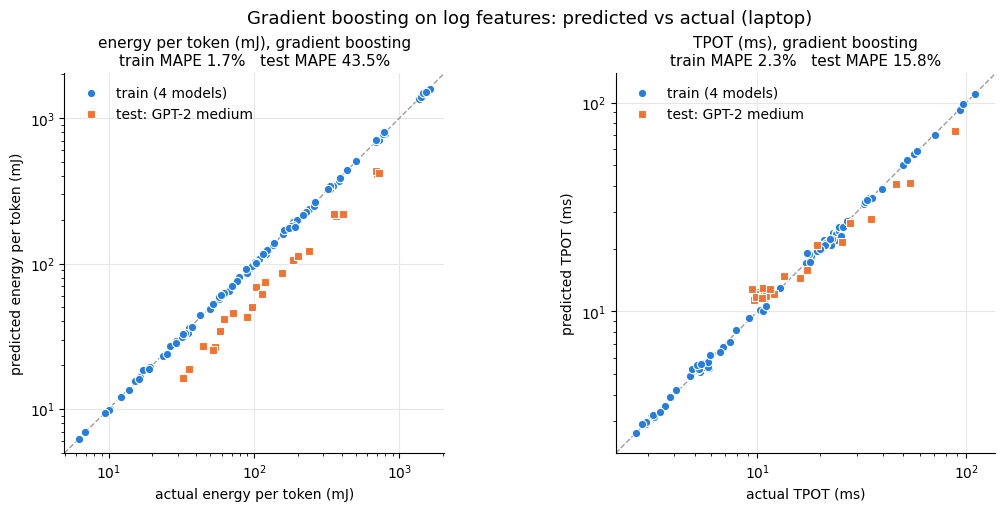

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, t in zip(axes, BASELINES):
    preds = predict_gbr(t, cfg)
    lo = min(cfg[t].min(), preds.min()) * 0.8
    hi = max(cfg[t].max(), preds.max()) * 1.25
    for name, part, color, marker in [("train (4 models)", train, "#257de0", "o"),
                                      ("test: GPT-2 medium", test, "#f47230", "s")]:
        ax.scatter(part[t], predict_gbr(t, part), s=36, color=color, marker=marker,
                   edgecolor="white", linewidth=0.8, label=name, zorder=3)
    ax.plot([lo, hi], [lo, hi], color="#9c9c9c", linestyle="--", linewidth=1, zorder=2)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel(f"actual {LABELS[t]}"); ax.set_ylabel(f"predicted {LABELS[t]}")
    r = comparison.loc[(t, "gradient boosting, log features")]
    ax.set_title(f"{LABELS[t]}, gradient boosting\ntrain MAPE {r.iloc[0]:.1f}%   "
                 f"test MAPE {r.iloc[1]:.1f}%", fontsize=11)
    ax.grid(True, color="#e6e6e6", linewidth=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left")
fig.suptitle("Gradient boosting on log features: predicted vs actual (laptop)", fontsize=13)
plt.show()

# Phase 3, piece 4: small neural network

Same features, log targets and split. The features are standardized (mean 0, std 1) using only the training rows, so no feature dominates just because of its units.

Network: 2 hidden layers of 32 ReLU units, Adam. It trains until the loss stops improving (tolerance 1e-6 for 50 epochs in a row), with a cap of 5000 epochs.

Unlike trees, a network can predict outside the training range. But what it predicts for a new model depends a lot on the random starting weights. The main row uses seed 0 like the other models, and the next cell checks 5 seeds to see how much the test result changes.

In [67]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

MLP_MAX_EPOCHS = 5000


def make_mlp(seed):
    # The scaler is fit inside the pipeline, so it only ever sees training rows.
    return make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=MLP_MAX_EPOCHS, tol=1e-6,
                                      n_iter_no_change=50, random_state=seed))


mlp = {t: make_mlp(0).fit(log_features(train), np.log(train[t])) for t in BASELINES}
for t, m in mlp.items():
    epochs = m[-1].n_iter_
    assert epochs < MLP_MAX_EPOCHS, f"{t}: hit the epoch limit, not converged"
    print(f"{t:10s} converged after {epochs} epochs, final training loss {m[-1].loss_:.5f}")


def predict_mlp(t, df):
    return np.exp(mlp[t].predict(log_features(df)))

energy_mj  converged after 1497 epochs, final training loss 0.00069
tpot_ms    converged after 1113 epochs, final training loss 0.00056


In [68]:
# Every model so far, same split, same MAPE, plus the held-out predicted / actual ratio.
PREDICTORS["neural network (MLP 32x32), log features"] = predict_mlp
rows = []
for t in BASELINES:
    for name, fn in PREDICTORS.items():
        test_pred = fn(t, test)
        rows.append({"target": t, "model": name,
                     "train MAPE (%)": mape(train[t], fn(t, train)),
                     "test MAPE, GPT-2 medium (%)": mape(test[t], test_pred),
                     "test mean predicted / actual": float((test_pred / test[t]).mean())})
comparison = pd.DataFrame(rows).set_index(["target", "model"]).round(2)
comparison

train MAPE (%)  \
target    model                                                      
energy_mj baseline, raw-space fit                           124.34   
          baseline, log-space fit                            35.56   
          linear regression, log features                    23.15   
          gradient boosting, log features                     1.72   
          neural network (MLP 32x32), log features            2.56   
tpot_ms   baseline, raw-space fit                            74.93   
          baseline, log-space fit                            43.97   
          linear regression, log features                    22.73   
          gradient boosting, log features                     2.29   
          neural network (MLP 32x32), log features            2.64   

                                                    test MAPE, GPT-2 medium (%)  \
target    model                                                                   
energy_mj baseline, raw-space fit                                         32.63   
          baseline, log-space fit                                         28.71   
          linear regression, log features                                 90.32   
          gradient boosting, log features                                 43.55   
          neural network (MLP 32x32), log features                       394.43   
tpot_ms   baseline, raw-space fit                                         52.20   
          baseline, log-space fit                                         41.68   
          linear regression, log features                                 83.00   
          gradient boosting, log features                                 15.76   
          neural network (MLP 32x32), log features                        19.00   

                                                    test mean predicted / actual  
target    model                                                                   
energy_mj baseline, raw-space fit                                           1.22  
          baseline, log-space fit                                           0.91  
          linear regression, log features                                   1.88  
          gradient boosting, log features                                   0.56  
          neural network (MLP 32x32), log features                          4.94  
tpot_ms   baseline, raw-space fit                                           1.23  
          baseline, log-space fit                                           1.07  
          linear regression, log features                                   1.79  
          gradient boosting, log features                                   1.07  
          neural network (MLP 32x32), log features                          1.16

In [69]:
# Seed check: same network, same data, only the initial weights change.
rows = []
for t in BASELINES:
    for seed in range(5):
        m = make_mlp(seed).fit(log_features(train), np.log(train[t]))
        tr_pred = np.exp(m.predict(log_features(train)))
        te_pred = np.exp(m.predict(log_features(test)))
        rows.append({"target": t, "seed": seed, "epochs": m[-1].n_iter_,
                     "train MAPE (%)": mape(train[t], tr_pred),
                     "test MAPE (%)": mape(test[t], te_pred),
                     "test predicted / actual": float((te_pred / test[t]).mean())})
seeds = pd.DataFrame(rows)
display(seeds.pivot_table(index="seed", columns="target",
                          values=["train MAPE (%)", "test MAPE (%)", "test predicted / actual"]).round(2))
seeds.groupby("target")[["train MAPE (%)", "test MAPE (%)"]].agg(["min", "median", "max"]).round(1)

test MAPE (%)         test predicted / actual         train MAPE (%)  \
target     energy_mj tpot_ms               energy_mj tpot_ms      energy_mj   
seed                                                                          
0             394.43   19.00                    4.94    1.16           2.56   
1             564.16   85.27                    6.64    1.85           3.17   
2              64.67  178.91                    1.48    2.79           3.08   
3             762.16  135.01                    8.62    2.35           3.54   
4             803.99  205.26                    9.04    3.05           3.44   

                
target tpot_ms  
seed            
0         2.64  
1         2.71  
2         2.18  
3         3.43  
4         3.06

train MAPE (%)             test MAPE (%)              
                     min median  max           min median    max
target                                                          
energy_mj            2.6    3.2  3.5          64.7  564.2  804.0
tpot_ms              2.2    2.7  3.4          19.0  135.0  205.3

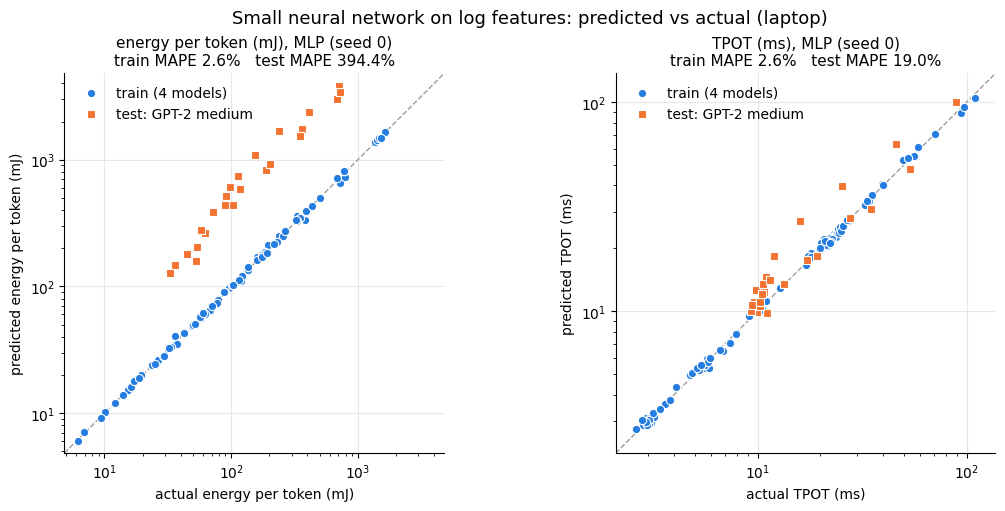

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, t in zip(axes, BASELINES):
    preds = predict_mlp(t, cfg)
    lo = min(cfg[t].min(), preds.min()) * 0.8
    hi = max(cfg[t].max(), preds.max()) * 1.25
    for name, part, color, marker in [("train (4 models)", train, "#257de0", "o"),
                                      ("test: GPT-2 medium", test, "#f47230", "s")]:
        ax.scatter(part[t], predict_mlp(t, part), s=36, color=color, marker=marker,
                   edgecolor="white", linewidth=0.8, label=name, zorder=3)
    ax.plot([lo, hi], [lo, hi], color="#9c9c9c", linestyle="--", linewidth=1, zorder=2)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel(f"actual {LABELS[t]}"); ax.set_ylabel(f"predicted {LABELS[t]}")
    r = comparison.loc[(t, "neural network (MLP 32x32), log features")]
    ax.set_title(f"{LABELS[t]}, MLP (seed 0)\ntrain MAPE {r.iloc[0]:.1f}%   "
                 f"test MAPE {r.iloc[1]:.1f}%", fontsize=11)
    ax.grid(True, color="#e6e6e6", linewidth=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left")
fig.suptitle("Small neural network on log features: predicted vs actual (laptop)", fontsize=13)
plt.show()

# Phase 3, piece 5: residual model

Use the formula for the overall scaling and let the trees learn only the correction.

1. Predict every row with the log-space baseline from piece 1 (fit on training rows only).
2. Residual = log(actual) − log(baseline prediction). 0 means the formula is right. +0.1 means the actual value is about 10% higher.
3. Train gradient boosting (same features, 200 trees of depth 3) to predict the residual, on training rows only.
4. Final prediction = baseline prediction × exp(predicted residual).

Plain gradient boosting has to predict the whole value, so for a new model it can only copy the size of a training model. Here the trees only predict a correction. The size comes from the formula, which uses params directly and works for any model size. If the trees don't help, the result should still be close to the baseline.

In [71]:
def residual_target(t, df):
    # log(actual) - log(log-space baseline prediction)
    return np.log(df[t]) - np.log(predict(t, df, *coefs["log", t]))


resid_gbr = {t: GradientBoostingRegressor(max_depth=3, n_estimators=200, random_state=0)
                .fit(log_features(train), residual_target(t, train))
             for t in BASELINES}


def predict_residual(t, df):
    return predict(t, df, *coefs["log", t]) * np.exp(resid_gbr[t].predict(log_features(df)))


# What the trees are correcting: size of the baseline's residuals, and the features they used.
for t in BASELINES:
    r_tr, r_te = residual_target(t, train), residual_target(t, test)
    print(f"{t:10s} baseline residual, mean |log ratio|: train {r_tr.abs().mean():.3f}   "
          f"GPT-2 medium {r_te.abs().mean():.3f}")
pd.DataFrame({t: m.feature_importances_ for t, m in resid_gbr.items()}, index=FEATURES).round(3)

energy_mj  baseline residual, mean |log ratio|: train 0.348   GPT-2 medium 0.365
tpot_ms    baseline residual, mean |log ratio|: train 0.432   GPT-2 medium 0.487


,energy_mj,tpot_ms
log_params,0.203,0.090
log_batch,0.343,0.657
log_prompt,0.177,0.111
layers,0.177,0.061
kv_heads,0.101,0.081


In [72]:
# Every model, same split, same MAPE, plus the held-out predicted / actual ratio.
PREDICTORS["residual: log baseline x gradient boosting"] = predict_residual
rows = []
for t in BASELINES:
    for name, fn in PREDICTORS.items():
        test_pred = fn(t, test)
        rows.append({"target": t, "model": name,
                     "train MAPE (%)": mape(train[t], fn(t, train)),
                     "test MAPE, GPT-2 medium (%)": mape(test[t], test_pred),
                     "test mean predicted / actual": float((test_pred / test[t]).mean())})
comparison = pd.DataFrame(rows).set_index(["target", "model"]).round(2)
comparison

train MAPE (%)  \
target    model                                                        
energy_mj baseline, raw-space fit                             124.34   
          baseline, log-space fit                              35.56   
          linear regression, log features                      23.15   
          gradient boosting, log features                       1.72   
          neural network (MLP 32x32), log features              2.56   
          residual: log baseline x gradient boosting            2.07   
tpot_ms   baseline, raw-space fit                              74.93   
          baseline, log-space fit                              43.97   
          linear regression, log features                      22.73   
          gradient boosting, log features                       2.29   
          neural network (MLP 32x32), log features              2.64   
          residual: log baseline x gradient boosting            2.13   

                                                      test MAPE, GPT-2 medium (%)  \
target    model                                                                     
energy_mj baseline, raw-space fit                                           32.63   
          baseline, log-space fit                                           28.71   
          linear regression, log features                                   90.32   
          gradient boosting, log features                                   43.55   
          neural network (MLP 32x32), log features                         394.43   
          residual: log baseline x gradient boosting                        20.86   
tpot_ms   baseline, raw-space fit                                           52.20   
          baseline, log-space fit                                           41.68   
          linear regression, log features                                   83.00   
          gradient boosting, log features                                   15.76   
          neural network (MLP 32x32), log features                          19.00   
          residual: log baseline x gradient boosting                        22.03   

                                                      test mean predicted / actual  
target    model                                                                     
energy_mj baseline, raw-space fit                                             1.22  
          baseline, log-space fit                                             0.91  
          linear regression, log features                                     1.88  
          gradient boosting, log features                                     0.56  
          neural network (MLP 32x32), log features                            4.94  
          residual: log baseline x gradient boosting                          1.03  
tpot_ms   baseline, raw-space fit                                             1.23  
          baseline, log-space fit                                             1.07  
          linear regression, log features                                     1.79  
          gradient boosting, log features                                     1.07  
          neural network (MLP 32x32), log features                            1.16  
          residual: log baseline x gradient boosting                          1.15

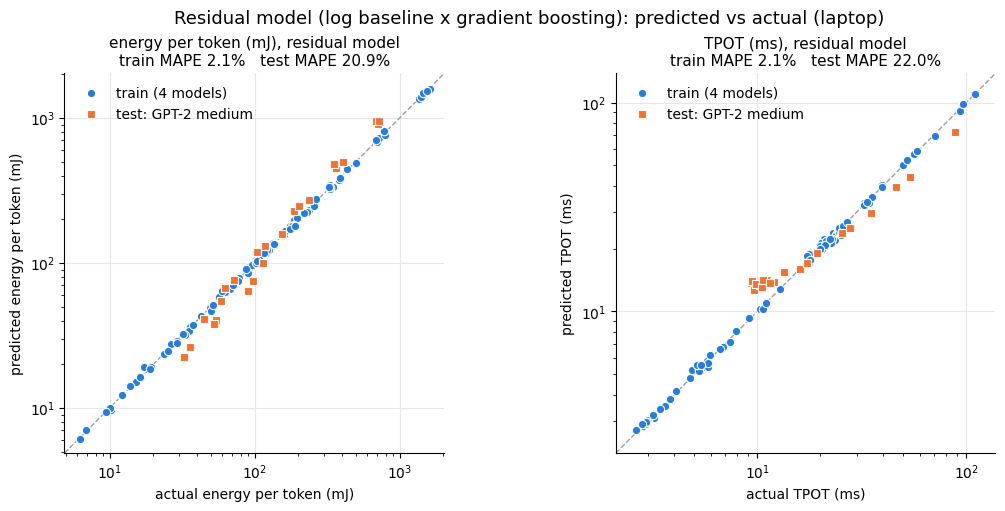

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, t in zip(axes, BASELINES):
    preds = predict_residual(t, cfg)
    lo = min(cfg[t].min(), preds.min()) * 0.8
    hi = max(cfg[t].max(), preds.max()) * 1.25
    for name, part, color, marker in [("train (4 models)", train, "#257de0", "o"),
                                      ("test: GPT-2 medium", test, "#f47230", "s")]:
        ax.scatter(part[t], predict_residual(t, part), s=36, color=color, marker=marker,
                   edgecolor="white", linewidth=0.8, label=name, zorder=3)
    ax.plot([lo, hi], [lo, hi], color="#9c9c9c", linestyle="--", linewidth=1, zorder=2)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel(f"actual {LABELS[t]}"); ax.set_ylabel(f"predicted {LABELS[t]}")
    r = comparison.loc[(t, "residual: log baseline x gradient boosting")]
    ax.set_title(f"{LABELS[t]}, residual model\ntrain MAPE {r.iloc[0]:.1f}%   "
                 f"test MAPE {r.iloc[1]:.1f}%", fontsize=11)
    ax.grid(True, color="#e6e6e6", linewidth=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left")
fig.suptitle("Residual model (log baseline x gradient boosting): predicted vs actual (laptop)", fontsize=13)
plt.show()

# Phase 3, Split A: random 80/20

This is the easy case. All five LLMs are mixed together and 20% of the configs are held out at random (seed 0, so it's reproducible). Every test config comes from a model the predictor has already seen in training, so this measures how well each predictor fills in missing batch sizes and prompt lengths, not how well it handles a new model.

Same features, same log targets, same settings as before. Everything is refit on the Split A training rows only. The table puts Split A next to Split B (GPT-2 medium held out) from above.

In [74]:
from sklearn.model_selection import train_test_split

train_a, test_a = train_test_split(cfg, test_size=0.2, random_state=0)
train_a, test_a = train_a.reset_index(drop=True), test_a.reset_index(drop=True)
print(f"Split A  train: {len(train_a)} configs   test: {len(test_a)} configs")
print("test configs per model:")
print(test_a["model"].value_counts().sort_index())

Split A  train: 95 configs   test: 24 configs
test configs per model:
model
Qwen/Qwen2.5-0.5B               6
TinyLlama/TinyLlama_v1.1        5
distilbert/distilgpt2           5
openai-community/gpt2           4
openai-community/gpt2-medium    4
Name: count, dtype: int64


In [75]:
def fit_all(tr):
    # Fit every predictor on the rows in tr. Returns {name: function(t, df) -> prediction}.
    # Same methods and settings as the Split B cells above, just trained on different rows.
    preds = {}
    raw_c, log_c, lin, gb, nn, res = {}, {}, {}, {}, {}, {}
    for t in BASELINES:
        x = BASELINES[t](tr)
        X = np.column_stack([x, np.ones(len(x))])
        (a, c), *_ = np.linalg.lstsq(X, tr[t], rcond=None)
        raw_c[t] = (a, c)

        xv, yv = x.to_numpy(), tr[t].to_numpy()
        fit = least_squares(lambda th: np.log(th[0] * xv + th[1]) - np.log(yv),
                            x0=np.clip([a, c], 1e-6, None), bounds=([0, 0], [np.inf, np.inf]))
        assert fit.success, fit.message
        log_c[t] = tuple(fit.x)

        F, logy = log_features(tr), np.log(tr[t])
        lin[t] = LinearRegression().fit(F, logy)
        gb[t] = GradientBoostingRegressor(max_depth=3, n_estimators=200, random_state=0).fit(F, logy)
        nn[t] = make_mlp(0).fit(F, logy)
        assert nn[t][-1].n_iter_ < MLP_MAX_EPOCHS, f"{t}: MLP hit the epoch limit"
        resid = logy - np.log(predict(t, tr, *log_c[t]))
        res[t] = GradientBoostingRegressor(max_depth=3, n_estimators=200, random_state=0).fit(F, resid)

    preds["baseline, raw-space fit"] = lambda t, df: predict(t, df, *raw_c[t])
    preds["baseline, log-space fit"] = lambda t, df: predict(t, df, *log_c[t])
    preds["linear regression, log features"] = lambda t, df: np.exp(lin[t].predict(log_features(df)))
    preds["gradient boosting, log features"] = lambda t, df: np.exp(gb[t].predict(log_features(df)))
    preds["neural network (MLP 32x32), log features"] = lambda t, df: np.exp(nn[t].predict(log_features(df)))
    preds["residual: log baseline x gradient boosting"] = (
        lambda t, df: predict(t, df, *log_c[t]) * np.exp(res[t].predict(log_features(df))))
    return preds


split_a = fit_all(train_a)

In [76]:
# Split A next to Split B. Split B numbers are the held-out GPT-2 medium results from above.
rows = []
for t in BASELINES:
    for name, fn in split_a.items():
        rows.append({"target": t, "model": name,
                     "A: train MAPE (%)": mape(train_a[t], fn(t, train_a)),
                     "A: test MAPE (%)": mape(test_a[t], fn(t, test_a)),
                     "B: train MAPE (%)": comparison.loc[(t, name), "train MAPE (%)"],
                     "B: test MAPE, GPT-2 medium (%)": comparison.loc[(t, name), "test MAPE, GPT-2 medium (%)"]})
splits = pd.DataFrame(rows).set_index(["target", "model"]).round(1)
splits

A: train MAPE (%)  \
target    model                                                           
energy_mj baseline, raw-space fit                                 100.9   
          baseline, log-space fit                                  34.1   
          linear regression, log features                          22.4   
          gradient boosting, log features                           1.7   
          neural network (MLP 32x32), log features                  2.6   
          residual: log baseline x gradient boosting                2.2   
tpot_ms   baseline, raw-space fit                                  69.1   
          baseline, log-space fit                                  42.8   
          linear regression, log features                          22.3   
          gradient boosting, log features                           2.2   
          neural network (MLP 32x32), log features                  2.1   
          residual: log baseline x gradient boosting                2.0   

                                                      A: test MAPE (%)  \
target    model                                                          
energy_mj baseline, raw-space fit                                 89.1   
          baseline, log-space fit                                 44.4   
          linear regression, log features                         28.1   
          gradient boosting, log features                          5.9   
          neural network (MLP 32x32), log features                 6.0   
          residual: log baseline x gradient boosting               8.7   
tpot_ms   baseline, raw-space fit                                 82.2   
          baseline, log-space fit                                 50.3   
          linear regression, log features                         27.5   
          gradient boosting, log features                          9.9   
          neural network (MLP 32x32), log features                 9.6   
          residual: log baseline x gradient boosting               8.9   

                                                      B: train MAPE (%)  \
target    model                                                           
energy_mj baseline, raw-space fit                                 124.3   
          baseline, log-space fit                                  35.6   
          linear regression, log features                          23.2   
          gradient boosting, log features                           1.7   
          neural network (MLP 32x32), log features                  2.6   
          residual: log baseline x gradient boosting                2.1   
tpot_ms   baseline, raw-space fit                                  74.9   
          baseline, log-space fit                                  44.0   
          linear regression, log features                          22.7   
          gradient boosting, log features                           2.3   
          neural network (MLP 32x32), log features                  2.6   
          residual: log baseline x gradient boosting                2.1   

                                                      B: test MAPE, GPT-2 medium (%)  
target    model                                                                       
energy_mj baseline, raw-space fit                                               32.6  
          baseline, log-space fit                                               28.7  
          linear regression, log features                                       90.3  
          gradient boosting, log features                                       43.6  
          neural network (MLP 32x32), log features                             394.4  
          residual: log baseline x gradient boosting                            20.9  
tpot_ms   baseline, raw-space fit                                               52.2  
          baseline, log-space fit                                               41.7  
          linear regression, log features    

# Transfer experiment: train on the laptop, test on the T4

Train all five models on every laptop config, then test them on every T4 config. Both CSVs are averaged over the 3 repeats, the same way as before. Same features, same log targets, same settings. Energy is total energy per token, the same definition as Split B.

The spec says not to mix GPUs in one training set, so the T4 is only used for testing here. The question is how far a predictor trained on one GPU carries over to another.

This section adds a third target, TTFT. Its baseline formula is:

TTFT ≈ a · params · batch · prompt_len + c

Prefill runs the whole prompt for the whole batch in one pass. The work is about 2 × params operations per token, and there are batch × prompt_len tokens, so the time grows with params × batch × prompt_len. c is a fixed overhead. In the code, params is in billions and the product is divided by 1000 so a is an easy number to read.

At the end, the baseline's two constants are fit on the T4 data alone. That shows how much of the transfer error is just the constants (the T4 is a different speed) and how much is the formula itself.

This section has its own helper functions, so nothing in Split A or Split B changes.

In [77]:
# Three targets here. Energy and TPOT use the same baseline formulas as before; TTFT is new.
TRANSFER_X = {
    "energy_mj": lambda df: df["params_b"] / df["batch_size"],                         # a * params / batch + c
    "ttft_ms":   lambda df: df["params_b"] * df["batch_size"] * df["prompt_len"] / 1000, # a * params * batch * prompt + c
    "tpot_ms":   lambda df: df["params_b"],                                            # a * params + c
}
TRANSFER_LABELS = {"energy_mj": "energy per token (mJ)", "ttft_ms": "TTFT (ms)", "tpot_ms": "TPOT (ms)"}


def load_configs(path):
    # ok rows only, mean over the 3 repeats of each config. Same as cfg above, plus TTFT.
    d = pd.read_csv(path)
    d = d[d["status"] == "ok"]
    out = (d.groupby(["model", "params", "layers", "kv_heads", "batch_size", "prompt_len"], as_index=False)
             .agg(energy_mj=("energy_per_token_j", lambda s: s.mean() * 1000),
                  ttft_ms=("ttft_s", lambda s: s.mean() * 1000),
                  tpot_ms=("tpot_s", lambda s: s.mean() * 1000)))
    out["params_b"] = out["params"] / 1e9
    return out


laptop = load_configs(DATA / "sweep_v2_nvidia_geforce_rtx_5070_ti_laptop_gpu.csv")
t4 = load_configs(DATA / "sweep_v2_tesla_t4.csv")
print(f"laptop: {len(laptop)} configs (train)   T4: {len(t4)} configs (test)")

laptop: 119 configs (train)   T4: 120 configs (test)


In [78]:
def fit_baseline_log(df, t):
    # Log-space fit of a and c, started from the raw least-squares answer. Same method as piece 1.
    x, y = TRANSFER_X[t](df).to_numpy(), df[t].to_numpy()
    (a, c), *_ = np.linalg.lstsq(np.column_stack([x, np.ones(len(x))]), y, rcond=None)
    fit = least_squares(lambda th: np.log(th[0] * x + th[1]) - np.log(y),
                        x0=np.clip([a, c], 1e-6, None), bounds=([0, 0], [np.inf, np.inf]))
    assert fit.success, fit.message
    return tuple(fit.x)


def baseline_pred(df, t, ac):
    return ac[0] * TRANSFER_X[t](df) + ac[1]


def fit_transfer(tr):
    # All five models on the rows in tr, for all three targets. Same settings as the cells above.
    models = {}
    for t in TRANSFER_X:
        ac = fit_baseline_log(tr, t)
        F, logy = log_features(tr), np.log(tr[t])
        nn = make_mlp(0).fit(F, logy)
        assert nn[-1].n_iter_ < MLP_MAX_EPOCHS, f"{t}: MLP hit the epoch limit"
        resid = logy - np.log(baseline_pred(tr, t, ac))
        models[t] = {
            "baseline": ac,
            "linear": LinearRegression().fit(F, logy),
            "gbm": GradientBoostingRegressor(max_depth=3, n_estimators=200, random_state=0).fit(F, logy),
            "mlp": nn,
            "residual": GradientBoostingRegressor(max_depth=3, n_estimators=200, random_state=0).fit(F, resid),
        }
    return models


def transfer_predict(models, name, t, df):
    m = models[t]
    if name == "baseline, log-space fit":
        return baseline_pred(df, t, m["baseline"])
    if name == "residual: log baseline x gradient boosting":
        return baseline_pred(df, t, m["baseline"]) * np.exp(m["residual"].predict(log_features(df)))
    key = {"linear regression, log features": "linear", "gradient boosting, log features": "gbm",
           "neural network (MLP 32x32), log features": "mlp"}[name]
    return np.exp(m[key].predict(log_features(df)))


TRANSFER_MODELS = ["baseline, log-space fit", "linear regression, log features",
                   "gradient boosting, log features", "neural network (MLP 32x32), log features",
                   "residual: log baseline x gradient boosting"]
laptop_models = fit_transfer(laptop)

In [79]:
# Trained on the laptop. "laptop MAPE" is the fit on its own training data, for reference.
rows = []
for t in TRANSFER_X:
    for name in TRANSFER_MODELS:
        on_t4 = transfer_predict(laptop_models, name, t, t4)
        rows.append({"target": t, "model": name,
                     "laptop MAPE (%)": mape(laptop[t], transfer_predict(laptop_models, name, t, laptop)),
                     "T4 MAPE (%)": mape(t4[t], on_t4),
                     "T4 mean predicted / actual": float((on_t4 / t4[t]).mean())})
transfer = pd.DataFrame(rows).set_index(["target", "model"]).round(2)
transfer

laptop MAPE (%)  \
target    model                                                         
energy_mj baseline, log-space fit                               36.76   
          linear regression, log features                       24.13   
          gradient boosting, log features                        1.78   
          neural network (MLP 32x32), log features               2.95   
          residual: log baseline x gradient boosting             2.23   
ttft_ms   baseline, log-space fit                               28.47   
          linear regression, log features                       31.18   
          gradient boosting, log features                        4.15   
          neural network (MLP 32x32), log features               2.44   
          residual: log baseline x gradient boosting             3.16   
tpot_ms   baseline, log-space fit                               44.29   
          linear regression, log features                       24.10   
          gradient boosting, log features                        2.62   
          neural network (MLP 32x32), log features               2.56   
          residual: log baseline x gradient boosting             2.36   

                                                      T4 MAPE (%)  \
target    model                                                     
energy_mj baseline, log-space fit                           28.87   
          linear regression, log features                   33.49   
          gradient boosting, log features                   29.17   
          neural network (MLP 32x32), log features          29.11   
          residual: log baseline x gradient boosting        29.34   
ttft_ms   baseline, log-space fit                           39.65   
          linear regression, log features                   39.65   
          gradient boosting, log features                   40.09   
          neural network (MLP 32x32), log features          39.92   
          residual: log baseline x gradient boosting        40.17   
tpot_ms   baseline, log-space fit                           38.74   
          linear regression, log features                   34.55   
          gradient boosting, log features                   37.05   
          neural network (MLP 32x32), log features          36.73   
          residual: log baseline x gradient boosting        36.96   

                                                      T4 mean predicted / actual  
target    model                                                                   
energy_mj baseline, log-space fit                                           1.04  
          linear regression, log features                                   1.05  
          gradient boosting, log features                                   1.04  
          neural network (MLP 32x32), log features                          1.04  
          residual: log baseline x gradient boosting                        1.04  
ttft_ms   baseline, log-space fit                                           0.60  
          linear regression, log features                                   0.62  
          gradient boosting, log features                                   0.60  
          neural network (MLP 32x32), log features                          0.60  
          residual: log baseline x gradient boosting                        0.60  
tpot_ms   baseline, log-space fit                                           0.81  
          linear regression, log features                                   0.76  
          gradient boosting, log features                                   0.75  
          neural network (MLP 32x32), log features                          0.74  
          residual: log baseline x gradient boosting                        0.75

In [80]:
# For comparison: the baseline's two constants fit on the T4 data alone, scored on the T4.
rows = []
for t in TRANSFER_X:
    ac_laptop = laptop_models[t]["baseline"]
    ac_t4 = fit_baseline_log(t4, t)
    rows.append({"target": t,
                 "a (laptop)": ac_laptop[0], "c (laptop)": ac_laptop[1],
                 "a (T4)": ac_t4[0], "c (T4)": ac_t4[1],
                 "T4 MAPE, laptop constants (%)": mape(t4[t], baseline_pred(t4, t, ac_laptop)),
                 "T4 MAPE, T4 constants (%)": mape(t4[t], baseline_pred(t4, t, ac_t4))})
pd.DataFrame(rows).set_index("target").round(2)

,a (laptop),c (laptop),a (T4),c (T4),"T4 MAPE, laptop constants (%)","T4 MAPE, T4 constants (%)"
target,,,,,,
energy_mj,2392.96,18.52,2428.34,20.30,28.87,30.05
ttft_ms,60.35,2.83,105.34,4.24,39.65,19.24
tpot_ms,37.46,1.66,36.99,6.55,38.74,41.81


# Memory: predicting peak memory and an OOM check

Target: `peak_mem_gb`, the most memory PyTorch allocated during the run (`torch.cuda.max_memory_allocated()`). It's used raw, not logged. Features: params, batch_size, prompt_len, layers, hidden_size, kv_heads, also raw.

Model: gradient boosting with the same settings as before (200 trees, depth 3, seed 0). Data: laptop CSV, `ok` rows averaged over the 3 repeats (the repeats agree to within 0.0001 GB). Same split as Split B: train on four models, test on GPT-2 medium.

Then an OOM check: a config is flagged if its predicted peak is above 11.5 GB. The laptop has 12 GB, so that leaves some headroom. The laptop had one real OOM: TinyLlama at batch 128, prompt 512. Its run failed, so it has no peak memory and isn't in the training data. The check is whether the model still flags it.

In [81]:
MEM_FEATURES = ["params", "batch_size", "prompt_len", "layers", "hidden_size", "kv_heads"]
OOM_CAP_GB = 11.5

mem = (runs[runs["status"] == "ok"]
       .groupby(["model"] + MEM_FEATURES, as_index=False)
       .agg(peak_mem_gb=("peak_mem_gb", "mean")))
mem_train = mem[mem["model"] != HELD_OUT].reset_index(drop=True)
mem_test = mem[mem["model"] == HELD_OUT].reset_index(drop=True)

mem_gbr = GradientBoostingRegressor(max_depth=3, n_estimators=200, random_state=0).fit(
    mem_train[MEM_FEATURES], mem_train["peak_mem_gb"])

rows = []
for name, part in [("train (4 models)", mem_train), ("test: GPT-2 medium", mem_test)]:
    pred = mem_gbr.predict(part[MEM_FEATURES])
    err = pred - part["peak_mem_gb"]
    rows.append({"split": name, "configs": len(part),
                 "MAPE (%)": mape(part["peak_mem_gb"], pred),
                 "mean abs error (GB)": float(err.abs().mean()),
                 "max abs error (GB)": float(err.abs().max()),
                 "mean predicted / actual": float((pred / part["peak_mem_gb"]).mean())})
print(f"largest peak in training data: {mem_train['peak_mem_gb'].max():.2f} GB")
pd.DataFrame(rows).set_index("split").round(3)

largest peak in training data: 9.46 GB


,configs,MAPE (%),mean abs error (GB),max abs error (GB),mean predicted / actual
split,,,,,
train (4 models),95,3.068,0.033,0.200,1.001
test: GPT-2 medium,24,20.767,0.573,2.788,0.952


In [82]:
# GPT-2 medium, largest configs: this is where errors matter for an OOM check.
(mem_test.assign(predicted_gb=mem_gbr.predict(mem_test[MEM_FEATURES]))
         .assign(error_gb=lambda d: d["predicted_gb"] - d["peak_mem_gb"])
         .sort_values("peak_mem_gb", ascending=False)
         [["batch_size", "prompt_len", "peak_mem_gb", "predicted_gb", "error_gb"]]
         .head(6).round(2))

,batch_size,prompt_len,peak_mem_gb,predicted_gb,error_gb
23,128,512,9.98,7.20,-2.79
22,128,256,5.67,3.23,-2.44
20,64,512,5.35,4.31,-1.05
21,128,128,4.04,1.93,-2.10
19,64,256,3.20,2.02,-1.18
17,32,512,3.04,2.57,-0.47


In [83]:
# OOM check on every laptop config, plus the real OOM config (which has no measured peak).
oom_rows = (runs[runs["status"] == "oom"]
            .groupby(["model"] + MEM_FEATURES, as_index=False).size().drop(columns="size"))
check = pd.concat([mem.assign(status="ok"), oom_rows.assign(status="oom", peak_mem_gb=np.nan)],
                  ignore_index=True)
check["predicted_gb"] = mem_gbr.predict(check[MEM_FEATURES])
check["flagged_oom"] = check["predicted_gb"] > OOM_CAP_GB

print(f"cap: {OOM_CAP_GB} GB")
print(pd.crosstab(check["status"], check["flagged_oom"],
                  rownames=["what happened"], colnames=["predicted OOM"]))
check[check["status"] == "oom"][["model", "batch_size", "prompt_len", "predicted_gb", "flagged_oom"]].round(2)

cap: 11.5 GB
predicted OOM  False  True 
what happened              
ok               119      0
oom                0      1


,model,batch_size,prompt_len,predicted_gb,flagged_oom
119,TinyLlama/TinyLlama_v1.1,128,512,11.6,True


## Memory part 2: analytical estimate

Instead of learning peak memory from scratch, compute most of it:

peak_mem ≈ weights + KV cache + activations

- weights = params × 2 bytes (fp16)
- KV cache = 2 × layers × kv_heads × head_dim × (prompt_len + 127) × batch × 2 bytes, with head_dim = hidden_size / heads. The first 2 is one K and one V; the cache holds the prompt plus the 127 decoded tokens.
- activations = k × batch × prompt_len × hidden_size. These are the temporary tensors during prefill. They depend on the architecture, so k is the one number that gets fit.

k is fit with least squares on the four training models only (the measured peak minus weights minus KV cache, against batch × prompt_len × hidden_size, no intercept). Everything else is computed. Bytes are divided by 1e9 to match `peak_mem_gb`.

Because weights and KV cache are computed from the model's shape, this estimate keeps growing with batch and prompt length past anything in the training data, which the trees can't do.

Optional extra: a small residual tree (100 trees of depth 2) trained on log(actual) − log(analytical), like the residual model for energy. Final = analytical × exp(predicted correction).

In [84]:
heads = runs.groupby("model")["heads"].first()


def mem_fixed_gb(df):
    # Weights + KV cache, computed from the model shape. Nothing fit here.
    head_dim = df["hidden_size"] / heads.loc[df["model"]].to_numpy()
    weights = df["params"] * 2
    kv_cache = 2 * df["layers"] * df["kv_heads"] * head_dim * (df["prompt_len"] + 127) * df["batch_size"] * 2
    return (weights + kv_cache) / 1e9


def mem_act_x(df):
    # batch x prompt_len x hidden_size, in units that give GB when multiplied by k (bytes).
    return df["batch_size"] * df["prompt_len"] * df["hidden_size"] / 1e9


# Fit k on the training models only: least squares for (peak - fixed) ~ k * x, no intercept.
x_act = mem_act_x(mem_train)
y_act = mem_train["peak_mem_gb"] - mem_fixed_gb(mem_train)
k_act = float((x_act * y_act).sum() / (x_act * x_act).sum())
print(f"k = {k_act:.1f} bytes per (batch x prompt_len x hidden_size)")


def predict_mem_analytical(df):
    return mem_fixed_gb(df) + k_act * mem_act_x(df)


# Optional: small residual tree on the log ratio, training models only.
mem_resid = GradientBoostingRegressor(max_depth=2, n_estimators=100, random_state=0).fit(
    mem_train[MEM_FEATURES], np.log(mem_train["peak_mem_gb"]) - np.log(predict_mem_analytical(mem_train)))


def predict_mem_residual(df):
    return predict_mem_analytical(df) * np.exp(mem_resid.predict(df[MEM_FEATURES]))


MEM_PREDICTORS = {
    "gradient boosting": lambda df: mem_gbr.predict(df[MEM_FEATURES]),
    "analytical (fit k only)": predict_mem_analytical,
    "analytical + residual tree": predict_mem_residual,
}

k = 61.0 bytes per (batch x prompt_len x hidden_size)


In [85]:
rows = []
for name, fn in MEM_PREDICTORS.items():
    for split, part in [("train (4 models)", mem_train), ("test: GPT-2 medium", mem_test)]:
        pred = np.asarray(fn(part))
        err = pred - part["peak_mem_gb"].to_numpy()
        rows.append({"model": name, "split": split,
                     "MAPE (%)": mape(part["peak_mem_gb"].to_numpy(), pred),
                     "mean abs error (GB)": float(np.abs(err).mean()),
                     "max abs error (GB)": float(np.abs(err).max()),
                     "mean predicted / actual": float((pred / part["peak_mem_gb"]).mean())})
pd.DataFrame(rows).set_index(["model", "split"]).round(3)

MAPE (%)  mean abs error (GB)  \
model                      split                                               
gradient boosting          train (4 models)       3.068                0.033   
                           test: GPT-2 medium    20.767                0.573   
analytical (fit k only)    train (4 models)      12.795                0.245   
                           test: GPT-2 medium    13.126                0.461   
analytical + residual tree train (4 models)       2.738                0.070   
                           test: GPT-2 medium    11.417                0.402   

                                               max abs error (GB)  \
model                      split                                    
gradient boosting          train (4 models)                 0.200   
                           test: GPT-2 medium               2.788   
analytical (fit k only)    train (4 models)                 2.246   
                           test: GPT-2 medium               2.862   
analytical + residual tree train (4 models)                 1.183   
                           test: GPT-2 medium               3.584   

                                               mean predicted / actual  
model                      split                                        
gradient boosting          train (4 models)                      1.001  
                           test: GPT-2 medium                    0.952  
analytical (fit k only)    train (4 models)                      1.082  
                           test: GPT-2 medium                    1.130  
analytical + residual tree train (4 models)                      1.001  
                           test: GPT-2 medium                    1.110

In [86]:
# Largest GPT-2 medium configs, all three predictors.
big = mem_test.sort_values("peak_mem_gb", ascending=False).head(6).copy()
for name, fn in MEM_PREDICTORS.items():
    big[name] = np.asarray(fn(big))
big[["batch_size", "prompt_len", "peak_mem_gb"] + list(MEM_PREDICTORS)].round(2)

,batch_size,prompt_len,peak_mem_gb,gradient boosting,analytical (fit k only),analytical + residual tree
23,128,512,9.98,7.20,12.85,13.57
22,128,256,5.67,3.23,7.58,6.67
20,64,512,5.35,4.31,6.78,7.04
21,128,128,4.04,1.93,4.94,4.04
19,64,256,3.20,2.02,4.14,3.70
17,32,512,3.04,2.57,3.74,3.88


In [87]:
# OOM check with the 11.5 GB cap, for each predictor, on every laptop config plus the real OOM.
rows = []
for name, fn in MEM_PREDICTORS.items():
    pred = np.asarray(fn(check))
    flagged = pred > OOM_CAP_GB
    is_oom = (check["status"] == "oom").to_numpy()
    oom_pred = float(pred[is_oom][0])
    rows.append({"model": name,
                 "real OOM flagged": bool(flagged[is_oom][0]),
                 "OOM config predicted (GB)": oom_pred,
                 "margin over cap (GB)": oom_pred - OOM_CAP_GB,
                 "configs that ran but were flagged": int((flagged & ~is_oom).sum()),
                 "configs that ran": int((~is_oom).sum())})
print(f"cap: {OOM_CAP_GB} GB")
pd.DataFrame(rows).set_index("model").round(2)

cap: 11.5 GB


,real OOM flagged,OOM config predicted (GB),margin over cap (GB),configs that ran but were flagged,configs that ran
model,,,,,
gradient boosting,True,11.60,0.10,0,119
analytical (fit k only),True,12.23,0.73,1,119
analytical + residual tree,True,13.86,2.36,1,119


In [88]:
# Which configs that actually ran get flagged, and by which predictor.
flags = check[["model", "batch_size", "prompt_len", "status", "peak_mem_gb"]].copy()
for name, fn in MEM_PREDICTORS.items():
    flags[name] = np.asarray(fn(check))
flagged_any = (flags[list(MEM_PREDICTORS)] > OOM_CAP_GB).any(axis=1)
flags[flagged_any].round(2)

,model,batch_size,prompt_len,status,peak_mem_gb,gradient boosting,analytical (fit k only),analytical + residual tree
118,openai-community/gpt2-medium,128,512,ok,9.98,7.2,12.85,13.57
119,TinyLlama/TinyLlama_v1.1,128,512,oom,NaN,11.6,12.23,13.86


## Memory part 3: two-regime analytical model

The additive formula adds the prefill activations on top of the full KV cache. But those two never exist at the same time. During prefill, the cache only holds the prompt, and the activations are there too. By the end of decode the cache holds prompt + 127 tokens, but the prefill activations are already freed. So the peak is whichever of the two moments is bigger:

peak = weights + max(prompt_KV + k × batch × prompt_len × hidden, full_KV)

- prompt_KV: KV cache for prompt_len tokens
- full_KV: KV cache for prompt_len + 127 tokens
- weights and the KV formula are the same as part 2

k is still the only fitted number, fit on the four training models only. Because of the max(), it's no longer a plain linear fit, so it uses `least_squares` (k ≥ 0), started from the additive k.

In [89]:
def kv_cache_gb(df, tokens):
    head_dim = df["hidden_size"] / heads.loc[df["model"]].to_numpy()
    return 2 * df["layers"] * df["kv_heads"] * head_dim * tokens * df["batch_size"] * 2 / 1e9


def mem_two_regime(df, k):
    weights = df["params"] * 2 / 1e9
    prefill = kv_cache_gb(df, df["prompt_len"]) + k * mem_act_x(df)   # end of prefill
    decode = kv_cache_gb(df, df["prompt_len"] + 127)                  # end of decode
    return weights + np.maximum(prefill, decode)


fit_k2 = least_squares(lambda th: mem_two_regime(mem_train, th[0]) - mem_train["peak_mem_gb"],
                       x0=[k_act], bounds=([0], [np.inf]))
assert fit_k2.success, fit_k2.message
k_two = float(fit_k2.x[0])
print(f"k (two-regime) = {k_two:.1f} bytes   (additive k was {k_act:.1f})")


def predict_mem_two_regime(df):
    return mem_two_regime(df, k_two)


MEM_PREDICTORS["two-regime analytical (fit k only)"] = predict_mem_two_regime

k (two-regime) = 68.0 bytes   (additive k was 61.0)


In [90]:
# Accuracy, all predictors so far.
rows = []
for name, fn in MEM_PREDICTORS.items():
    for split, part in [("train (4 models)", mem_train), ("test: GPT-2 medium", mem_test)]:
        pred = np.asarray(fn(part))
        err = pred - part["peak_mem_gb"].to_numpy()
        rows.append({"model": name, "split": split,
                     "MAPE (%)": mape(part["peak_mem_gb"].to_numpy(), pred),
                     "mean abs error (GB)": float(np.abs(err).mean()),
                     "max abs error (GB)": float(np.abs(err).max()),
                     "mean predicted / actual": float((pred / part["peak_mem_gb"]).mean())})
pd.DataFrame(rows).set_index(["model", "split"]).round(3)

MAPE (%)  \
model                              split                          
gradient boosting                  train (4 models)       3.068   
                                   test: GPT-2 medium    20.767   
analytical (fit k only)            train (4 models)      12.795   
                                   test: GPT-2 medium    13.126   
analytical + residual tree         train (4 models)       2.738   
                                   test: GPT-2 medium    11.417   
two-regime analytical (fit k only) train (4 models)       9.643   
                                   test: GPT-2 medium     5.191   

                                                       mean abs error (GB)  \
model                              split                                     
gradient boosting                  train (4 models)                  0.033   
                                   test: GPT-2 medium                0.573   
analytical (fit k only)            train (4 models)                  0.245   
                                   test: GPT-2 medium                0.461   
analytical + residual tree         train (4 models)                  0.070   
                                   test: GPT-2 medium                0.402   
two-regime analytical (fit k only) train (4 models)                  0.202   
                                   test: GPT-2 medium                0.197   

                                                       max abs error (GB)  \
model                              split                                    
gradient boosting                  train (4 models)                 0.200   
                                   test: GPT-2 medium               2.788   
analytical (fit k only)            train (4 models)                 2.246   
                                   test: GPT-2 medium               2.862   
analytical + residual tree         train (4 models)                 1.183   
                                   test: GPT-2 medium               3.584   
two-regime analytical (fit k only) train (4 models)                 1.961   
                                   test: GPT-2 medium               1.732   

                                                       mean predicted / actual  
model                              split                                        
gradient boosting                  train (4 models)                      1.001  
                                   test: GPT-2 medium                    0.952  
analytical (fit k only)            train (4 models)                      1.082  
                                   test: GPT-2 medium                    1.130  
analytical + residual tree         train (4 models)                      1.001  
                                   test: GPT-2 medium                    1.110  
two-regime analytical (fit k only) train (4 models)                      1.050  
                                   test: GPT-2 medium                    1.034

In [91]:
# GPT-2 medium at batch 128, every prompt length.
b128 = mem_test[mem_test["batch_size"] == 128].sort_values("prompt_len").copy()
for name, fn in MEM_PREDICTORS.items():
    b128[name] = np.asarray(fn(b128))
b128["two-regime: prefill side"] = (b128["params"] * 2 / 1e9 + kv_cache_gb(b128, b128["prompt_len"])
                                    + k_two * mem_act_x(b128))
b128["two-regime: decode side"] = b128["params"] * 2 / 1e9 + kv_cache_gb(b128, b128["prompt_len"] + 127)
b128[["prompt_len", "peak_mem_gb"] + list(MEM_PREDICTORS)
     + ["two-regime: prefill side", "two-regime: decode side"]].round(2)

,prompt_len,peak_mem_gb,gradient boosting,analytical (fit k only),analytical + residual tree,two-regime analytical (fit k only),two-regime: prefill side,two-regime: decode side
21,128,4.04,1.93,4.94,4.04,3.92,3.46,3.92
22,256,5.67,3.23,7.58,6.67,6.21,6.21,5.53
23,512,9.98,7.20,12.85,13.57,11.72,11.72,8.75


In [92]:
# OOM check again, 11.5 GB cap, every predictor.
rows = []
is_oom = (check["status"] == "oom").to_numpy()
for name, fn in MEM_PREDICTORS.items():
    pred = np.asarray(fn(check))
    flagged = pred > OOM_CAP_GB
    oom_pred = float(pred[is_oom][0])
    rows.append({"model": name,
                 "real OOM flagged": bool(flagged[is_oom][0]),
                 "OOM config predicted (GB)": oom_pred,
                 "margin over cap (GB)": oom_pred - OOM_CAP_GB,
                 "configs that ran but were flagged": int((flagged & ~is_oom).sum())})
print(f"cap: {OOM_CAP_GB} GB")
pd.DataFrame(rows).set_index("model").round(2)

cap: 11.5 GB


,real OOM flagged,OOM config predicted (GB),margin over cap (GB),configs that ran but were flagged
model,,,,
gradient boosting,True,11.60,0.10,0
analytical (fit k only),True,12.23,0.73,1
analytical + residual tree,True,13.86,2.36,1
two-regime analytical (fit k only),True,12.80,1.30,1


In [93]:
# How well one k fits each model: predicted / actual range per model (two-regime).
(mem.assign(ratio=np.asarray(predict_mem_two_regime(mem)) / mem["peak_mem_gb"])
    .groupby("model")["ratio"].agg(["min", "median", "max"]).round(2))

,min,median,max
model,,,
Qwen/Qwen2.5-0.5B,0.77,0.99,1.17
TinyLlama/TinyLlama_v1.1,0.79,1.00,1.21
distilbert/distilgpt2,0.95,1.14,1.37
openai-community/gpt2,0.94,1.06,1.27
openai-community/gpt2-medium,0.97,1.01,1.17
